# ABA Framework 

On construit un framework ABA à la main, on regarde flat / circular / atomic, puis arguments + attaques.
Deux exemples: un sans cycle, un avec cycles.

## Étape 1 — Littéraux $L$

$$L = \{a,b,c,q,p,r,s,t\}$$


In [21]:
# ensemble des littéraux du framework
L = {"a", "b", "c", "q", "p", "r", "s", "t"}

print("L =", L)
print("b in L ?", "b" in L)
print("w in L ?", "w" in L)  # w n'existe pas
assert len(L) == 8

L = {'s', 'q', 't', 'c', 'a', 'b', 'r', 'p'}
b in L ? True
w in L ? False


## Étape 2 — Hypothèses $A$

$$A = \{a,b,c\}$$

In [22]:
# les hypothèses doivent être un sous-ensemble de L
A = {"a", "b", "c"}

print("A =", A)
print("A ⊆ L ?", A.issubset(L))
assert A <= L

A = {'c', 'a', 'b'}
A ⊆ L ? True


## Étape 3 — Contraires

$$\bar a = r,\quad \bar b = s,\quad \bar c = t$$

In [23]:
# chaque hypothèse a exactement un contraire dans L
contraries = {"a": "r", "b": "s", "c": "t"}

print("contrary(a) =", contraries["a"])
assert contraries["a"] == "r"
assert set(contraries) == A
assert set(contraries.values()) <= L

contrary(a) = r


## Étape 4 — Règles $R$

| Rule | Conclusion | Premises |
|------|------------|----------|
| $r_1$ | $p$ | $q, a$ |
| $r_2$ | $q$ | *(none — fact)* |
| $r_3$ | $r$ | $b, c$ |
| $r_4$ | $t$ | $p, c$ |
| $r_5$ | $s$ | $t$ |


In [24]:
from pathlib import Path
import sys

# racine du projet (dossier qui contient backend/)
PROJECT_ROOT = Path(r"C:\work univ\Argumentation-Theory-Project\part-aba")
sys.path.insert(0, str(PROJECT_ROOT))

from backend.aba_framework import Rule

# r2 est un fait (corps vide)
R = [
    Rule(conclusion="p", premises=("q", "a"), name="r1"),
    Rule(conclusion="q", premises=(), name="r2"),
    Rule(conclusion="r", premises=("b", "c"), name="r3"),
    Rule(conclusion="t", premises=("p", "c"), name="r4"),
    Rule(conclusion="s", premises=("t",), name="r5"),
]

for rule in R:
    print(rule)

assert R[1].conclusion == "q" and R[1].premises == ()

r1: p <- q, a
r2: q <-
r3: r <- b, c
r4: t <- p, c
r5: s <- t


## Étape 5 — Assembler le framework

In [25]:
import importlib
import backend.aba_framework as aba_framework

# reload utile si on modifie le code backend pendant le notebook
aba_framework = importlib.reload(aba_framework)
ABAFramework = aba_framework.ABAFramework

fw = ABAFramework.from_components(L, A, contraries, R)
print(fw.summary())
print("\nFlat?", fw.isFlat())  # flat = aucune hyp. n'est conclusion d'une règle

ABA Framework
  L = {a, b, c, p, q, r, s, t}
  A = {a, b, c}
  Contraries:
    contrary(a) = r
    contrary(b) = s
    contrary(c) = t
  Rules:
    r1: p <- q, a
    r2: q <-
    r3: r <- b, c
    r4: t <- p, c
    r5: s <- t

Flat? True


## Étape 6 — Checklist de validation

- [x] 8 literals
- [x] 3 assumptions ⊆ L
- [x] 3 contraries
- [x] 5 rules
- [x] fact $q \leftarrow$
- [x] all rule literals ∈ L

In [26]:
# quelques checks basiques avant de continuer
assert len(fw.literals) == 8
assert fw.assumptions <= fw.literals and len(fw.assumptions) == 3
assert len(fw.contraries) == 3
assert len(fw.rules) == 5
assert any(r.conclusion == "q" and r.premises == () for r in fw.rules)
for r in fw.rules:
    assert r.conclusion in fw.literals
    assert all(p in fw.literals for p in r.premises)
print("All validation checks passed.")

All validation checks passed.


## Conversion: non-circular & atomic

Sur cet exemple-là il n'y a **pas** de cycle. On vérifie quand même, puis on force la forme atomique.

In [27]:
# graphe de dépendances: conclusion -> prémisses
dep = fw.graphDependency()
print("Dependency graph:")
for lit, parents in sorted(dep.items()):
    print(f"  {lit} <- {parents if parents else '{}'}")

print("\nCircular dependencies?", fw.contains_circular_dependenncies())
fw_nc = fw.to_non_circular()
print("After to_non_circular, circular?", fw_nc.contains_circular_dependenncies())

print("\nOriginally atomic?", fw.isAtomic())
fw_at = fw.make_atomic()
print("After make_atomic, atomic?", fw_at.isAtomic())
print(fw_at.summary())

Dependency graph:
  a <- {}
  b <- {}
  c <- {}
  p <- {'q', 'a'}
  q <- {}
  r <- {'c', 'b'}
  s <- {'t'}
  t <- {'c', 'p'}

Circular dependencies? False
After to_non_circular, circular? False

Originally atomic? False
After make_atomic, atomic? True
ABA Framework
  L = {a, a_r1, a_r3, a_r4, a_r5, b, c, fail_r1, fail_r3, fail_r4, fail_r5, p, q, r, s, t}
  A = {a, a_r1, a_r3, a_r4, a_r5, b, c}
  Contraries:
    contrary(a) = r
    contrary(a_r1) = fail_r1
    contrary(a_r3) = fail_r3
    contrary(a_r4) = fail_r4
    contrary(a_r5) = fail_r5
    contrary(b) = s
    contrary(c) = t
  Rules:
    r1: p <- a_r1
    r2: q <-
    r3: r <- a_r3
    r4: t <- a_r4
    r5: s <- a_r5


### Graphe de dépendances (ex. 1)

Flèche `u → v` = `v` apparaît dans le corps d'une règle qui conclut `u`.

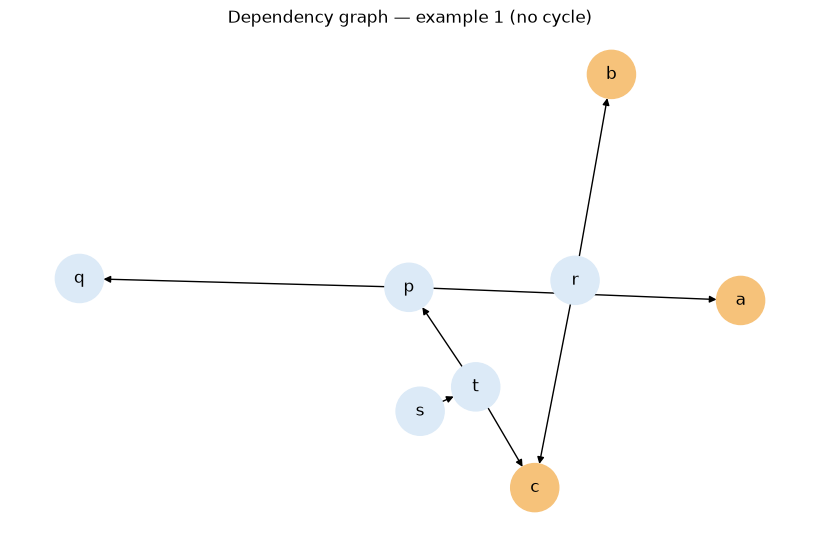

In [28]:
import matplotlib.pyplot as plt
import networkx as nx

# on dessine le graphe de dépendances du 1er exemple
G_dep = nx.DiGraph()
for lit in fw.literals:
    G_dep.add_node(lit)
for head, body in fw.graphDependency().items():
    for p in body:
        G_dep.add_edge(head, p)

plt.figure(figsize=(8, 5))
pos = nx.spring_layout(G_dep, seed=1)
# hypothèses en orange, le reste en bleu clair
colors = ["#f6c27a" if n in fw.assumptions else "#dceaf7" for n in G_dep.nodes()]
nx.draw(G_dep, pos, with_labels=True, node_size=1200, node_color=colors, arrows=True)
plt.title("Dependency graph — example 1 (no cycle)")
plt.axis("off")
plt.show()

## Exemple 2 — framework circulaire et non atomique

Autre exemple pour bien voir les cycles (`y <- y`, `x <- x`) et une règle non atomique (`z <- x, y`).

### Littéraux / Hypothèses / Contraires

$$L = \{a,b,x,y,z\},\quad A = \{a,b\}$$
$$\bar a = y,\quad \bar b = x$$

### Règles

| Rule | Conclusion | Premises |
|------|------------|----------|
| $r_1$ | $y$ | $b$ |
| $r_2$ | $y$ | $y$ |
| $r_3$ | $x$ | $x$ |
| $r_4$ | $x$ | $a$ |
| $r_5$ | $z$ | $x, y$ |

In [29]:
# 2e exemple: cycles + non atomique
L2 = {"a", "b", "x", "y", "z"}
A2 = {"a", "b"}
contraries2 = {"a": "y", "b": "x"}

R2 = [
    Rule(conclusion="y", premises=("b",), name="r1"),
    Rule(conclusion="y", premises=("y",), name="r2"),  # cycle sur y
    Rule(conclusion="x", premises=("x",), name="r3"),  # cycle sur x
    Rule(conclusion="x", premises=("a",), name="r4"),
    Rule(conclusion="z", premises=("x", "y"), name="r5"),  # 2 premisses => non atomique
]

fw2 = ABAFramework.from_components(L2, A2, contraries2, R2)
print(fw2.summary())
print("\nFlat?", fw2.isFlat())
print("Circular?", fw2.contains_circular_dependenncies())
print("Atomic?", fw2.isAtomic())

ABA Framework
  L = {a, b, x, y, z}
  A = {a, b}
  Contraries:
    contrary(a) = y
    contrary(b) = x
  Rules:
    r1: y <- b
    r2: y <- y
    r3: x <- x
    r4: x <- a
    r5: z <- x, y

Flat? True
Circular? True
Atomic? False


### Graphe de dépendances (ex. 2)

On voit clairement les boucles sur $x$ et $y$.

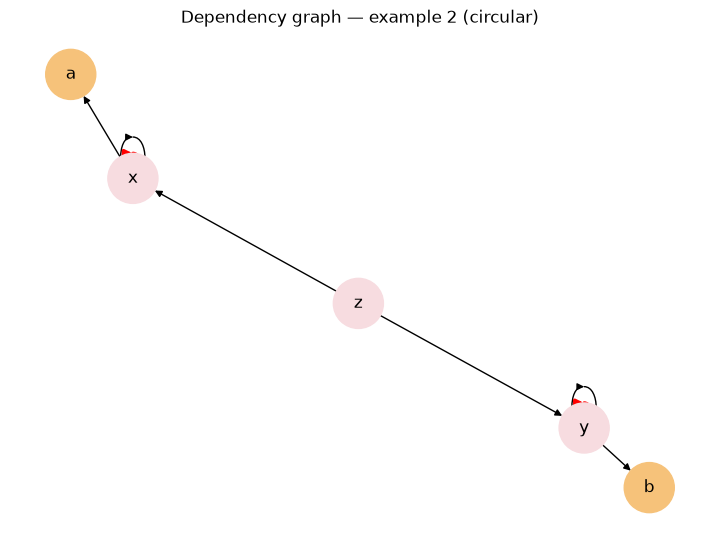

In [30]:
# dessin du graphe circulaire
G2 = nx.DiGraph()
for lit in fw2.literals:
    G2.add_node(lit)
for head, body in fw2.graphDependency().items():
    for p in body:
        G2.add_edge(head, p)

plt.figure(figsize=(7, 5))
pos2 = nx.spring_layout(G2, seed=7)
colors2 = ["#f6c27a" if n in fw2.assumptions else "#f7dce0" for n in G2.nodes()]
nx.draw(G2, pos2, with_labels=True, node_size=1300, node_color=colors2, arrows=True)
# surligner les self-loops (x->x, y->y)
loops = [(u, v) for u, v in G2.edges() if u == v]
if loops:
    nx.draw_networkx_edges(G2, pos2, edgelist=loops, edge_color="red", width=2.5, arrows=True)
plt.title("Dependency graph — example 2 (circular)")
plt.axis("off")
plt.show()

### Transformation `to_non_circular` puis `make_atomic`

In [31]:
# d'abord on casse les cycles
fw2_nc = fw2.to_non_circular()
print("After to_non_circular:")
print("  Circular?", fw2_nc.contains_circular_dependenncies())
print("  Flat?", fw2_nc.isFlat())
print("  Atomic?", fw2_nc.isAtomic())
print()
print(fw2_nc.summary())

# ensuite forme atomique (besoin d'être flat)
fw2_at = fw2_nc.make_atomic()
print("\nAfter make_atomic:")
print("  Atomic?", fw2_at.isAtomic())
print(fw2_at.summary())

After to_non_circular:
  Circular? False
  Flat? True
  Atomic? False

ABA Framework
  L = {a, b, x, x#0, x#1, x#2, y, y#0, y#1, y#2, z, z#0, z#1, z#2}
  A = {a, b}
  Contraries:
    contrary(a) = y
    contrary(b) = x
  Rules:
    alias_x: x <- x#0
    alias_y: y <- y#0
    alias_z: z <- z#0
    r1_L0: y#0 <- b
    r2_L0: y#0 <- y#1
    r3_L0: x#0 <- x#1
    r4_L0: x#0 <- a
    r5_L0: z#0 <- x#1, y#1
    r1_L1: y#1 <- b
    r2_L1: y#1 <- y#2
    r3_L1: x#1 <- x#2
    r4_L1: x#1 <- a
    r5_L1: z#1 <- x#2, y#2
    r1_L2: y#2 <- b
    r4_L2: x#2 <- a

After make_atomic:
  Atomic? True
ABA Framework
  L = {a, a_alias_x, a_alias_y, a_alias_z, a_r2_L0, a_r2_L1, a_r3_L0, a_r3_L1, a_r5_L0, a_r5_L1, b, fail_alias_x, fail_alias_y, fail_alias_z, fail_r2_L0, fail_r2_L1, fail_r3_L0, fail_r3_L1, fail_r5_L0, fail_r5_L1, x, x#0, x#1, x#2, y, y#0, y#1, y#2, z, z#0, z#1, z#2}
  A = {a, a_alias_x, a_alias_y, a_alias_z, a_r2_L0, a_r2_L1, a_r3_L0, a_r3_L1, a_r5_L0, a_r5_L1, b}
  Contraries:
    contrary(

### Graphe après `to_non_circular`

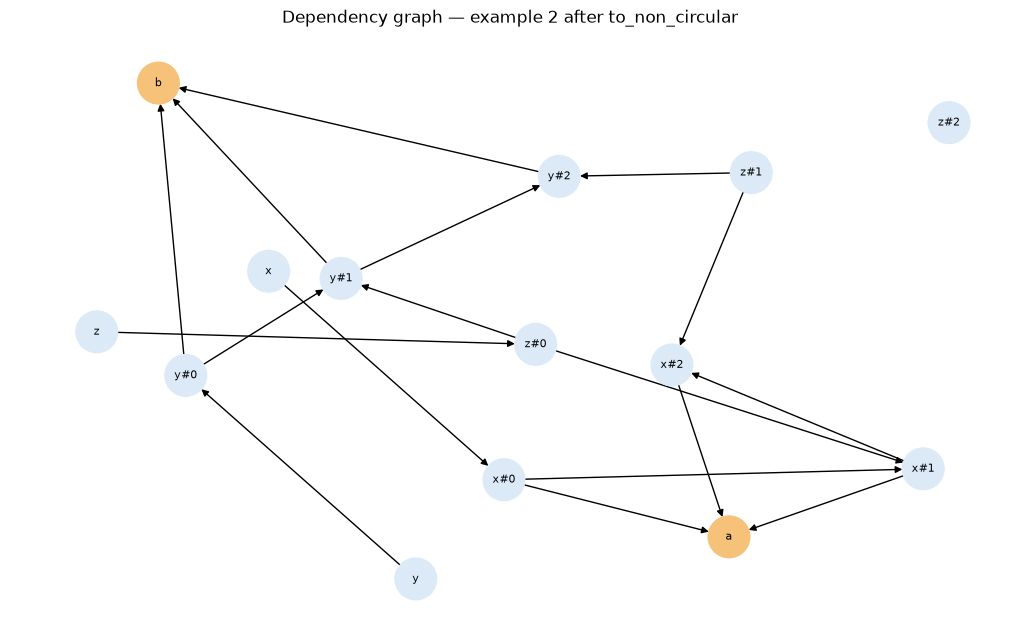

nb littéraux: 5 -> 14
nb règles: 5 -> 15


In [32]:
# même type de dessin, mais sur le framework sans cycle
G2nc = nx.DiGraph()
for lit in fw2_nc.literals:
    G2nc.add_node(lit)
for head, body in fw2_nc.graphDependency().items():
    for p in body:
        G2nc.add_edge(head, p)

plt.figure(figsize=(10, 6))
pos_nc = nx.spring_layout(G2nc, seed=3, k=0.9)
colors_nc = ["#f6c27a" if n in fw2_nc.assumptions else "#dceaf7" for n in G2nc.nodes()]
nx.draw(G2nc, pos_nc, with_labels=True, node_size=900, node_color=colors_nc,
        arrows=True, font_size=8)
plt.title("Dependency graph — example 2 after to_non_circular")
plt.axis("off")
plt.show()

print("nb littéraux:", len(fw2.literals), "->", len(fw2_nc.literals))
print("nb règles:", len(fw2.rules), "->", len(fw2_nc.rules))

### Arguments & attaques (ex. 2, framework d'origine)

Même sans transformation on peut déjà construire les arguments (les self-loops n'ajoutent pas de nouveaux supports).

5 arguments (ex. 2):

A1: a <- {a}
A2: b <- {b}
A3: x <- {a}
A4: y <- {b}
A5: z <- {a, b}

6 classical attacks:
  A3 -> A2 (on b)
  A3 -> A4 (on b)
  A3 -> A5 (on b)
  A4 -> A1 (on a)
  A4 -> A3 (on a)
  A4 -> A5 (on a)


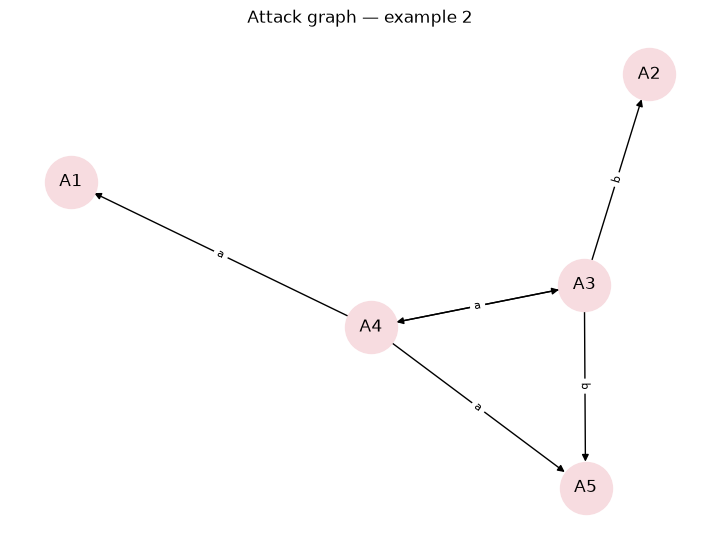

In [33]:
args2 = fw2.create_arguments()
print(f"{len(args2)} arguments (ex. 2):\n")
for arg in args2:
    print(arg)

att2 = fw2.attacks_classic(args2)
print(f"\n{len(att2)} classical attacks:")
for x, y, alpha in att2:
    print(f"  {x.name} -> {y.name} (on {alpha})")

# petit graphe d'attaques pour l'ex. 2
G_att2 = nx.DiGraph()
for arg in args2:
    G_att2.add_node(arg.name)
for x, y, alpha in att2:
    G_att2.add_edge(x.name, y.name, label=alpha)

plt.figure(figsize=(7, 5))
pos_a2 = nx.spring_layout(G_att2, seed=5)
nx.draw(G_att2, pos_a2, with_labels=True, node_size=1400, node_color="#f7dce0", arrows=True)
el2 = {(u, v): d["label"] for u, v, d in G_att2.edges(data=True)}
nx.draw_networkx_edge_labels(G_att2, pos_a2, edge_labels=el2, font_size=8)
plt.title("Attack graph — example 2")
plt.axis("off")
plt.show()

## Arguments (retour à l'ex. 1)

Un argument = claim déduit à partir d'hypothèses via $R$.
Les hypothèses elles-mêmes sont des arguments triviaux.

In [34]:
# génération des arguments pour le 1er framework
args = fw.create_arguments()
print(f"{len(args)} arguments:\n")
for arg in args:
    print(arg)

8 arguments:

A1: a <- {a}
A2: b <- {b}
A3: c <- {c}
A4: p <- {a}
A5: q <- {}
A6: r <- {b, c}
A7: s <- {a, c}
A8: t <- {a, c}


## Classical attacks

$X$ attacks $Y$ on assumption $\alpha$ iff $\mathrm{claim}(X) = \bar\alpha$ and $\alpha \in \mathrm{assumptions}(Y)$.

In [35]:
# attaque classique: claim(X) = contraire(alpha) et alpha in assumptions(Y)
attacks = fw.attacks_classic(args)
print(f"{len(attacks)} classical attacks:\n")
for x, y, alpha in attacks:
    print(f"{x.name} -> {y.name}  (on {alpha})   [{x.claim} <- {set(x.assumptions)}]")

10 classical attacks:

A6 -> A1  (on a)   [r <- {'c', 'b'}]
A6 -> A4  (on a)   [r <- {'c', 'b'}]
A6 -> A7  (on a)   [r <- {'c', 'b'}]
A6 -> A8  (on a)   [r <- {'c', 'b'}]
A7 -> A2  (on b)   [s <- {'c', 'a'}]
A7 -> A6  (on b)   [s <- {'c', 'a'}]
A8 -> A3  (on c)   [t <- {'c', 'a'}]
A8 -> A6  (on c)   [t <- {'c', 'a'}]
A8 -> A7  (on c)   [t <- {'c', 'a'}]
A8 -> A8  (on c)   [t <- {'c', 'a'}]


## Preferences — normal / reverse attacks (ABA+)

In [36]:
from backend.aba_framework import create_example

# b > a et c > a  (préférences sur les hypothèses)
fw_pref = create_example(preferences={"b": {"a"}, "c": {"a"}})
print(fw_pref.summary())

res = fw_pref.normal_reverse_attacks()
print(f"\nNormal attacks ({len(res['normal'])}):")
for x, y, alpha in res["normal"]:
    print(f"  {x.name} -> {y.name} (on {alpha})")

print(f"\nReverse attacks ({len(res['reverse'])}):")
for x, y, alpha in res["reverse"]:
    print(f"  {x.name} -> {y.name} (on {alpha})")

ABA Framework
  L = {a, b, c, p, q, r, s, t}
  A = {a, b, c}
  Contraries:
    contrary(a) = r
    contrary(b) = s
    contrary(c) = t
  Rules:
    r1: p <- q, a
    r2: q <-
    r3: r <- b, c
    r4: t <- p, c
    r5: s <- t

Normal attacks (4):
  A6 -> A1 (on a)
  A6 -> A4 (on a)
  A6 -> A7 (on a)
  A6 -> A8 (on a)

Reverse attacks (6):
  A2 -> A7 (on b)
  A6 -> A7 (on b)
  A3 -> A8 (on c)
  A6 -> A8 (on c)
  A7 -> A8 (on c)
  A8 -> A8 (on c)


## Attack graph (ex. 1)

Chaque nœud = un argument, chaque flèche = une attaque classique (label = hypothèse attaquée).

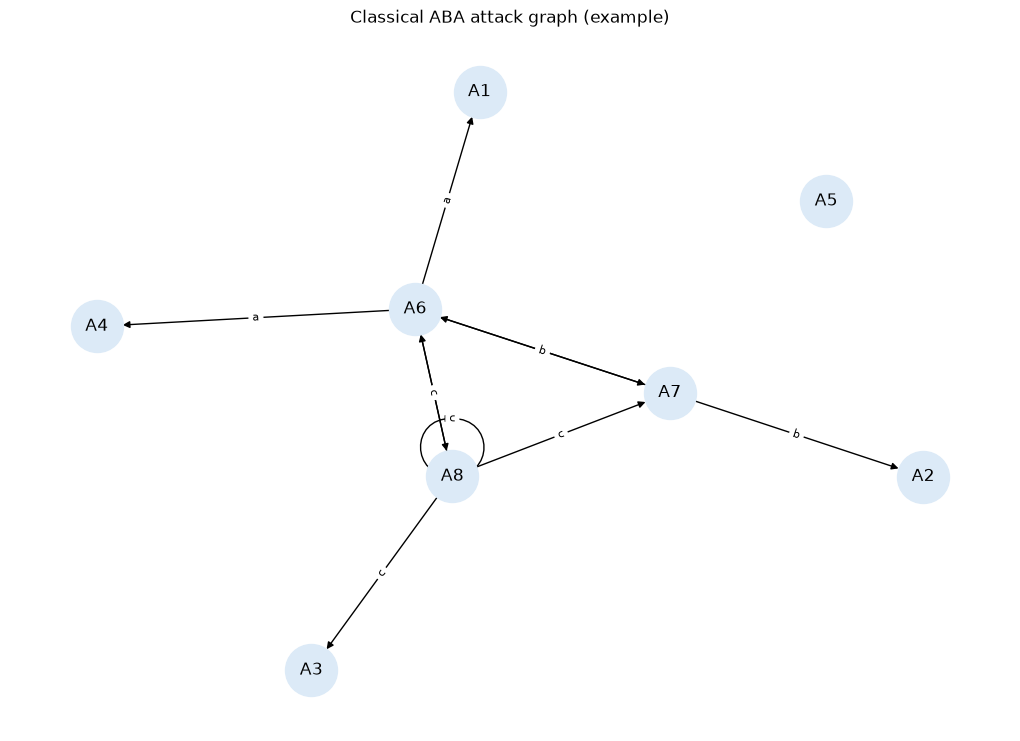

In [37]:
# graphe d'attaques classiques (ex. 1)
G = nx.DiGraph()
for arg in args:
    G.add_node(arg.name)
for x, y, alpha in attacks:
    G.add_edge(x.name, y.name, label=alpha)

plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_size=1400, node_color="#dceaf7", arrows=True)
edge_labels = {(u, v): d["label"] for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)
plt.title("Classical ABA attack graph (example)")
plt.axis("off")
plt.show()